## Bahnhofsuhr


Die [Schweizer Bahnhofsuhr](https://de.wikipedia.org/wiki/Schweizer_Bahnhofsuhr) ist Kult. Eine technische Zeichnung mit der Originalkonstruktion findest Du auf der [Webseite des Museums für Gestaltung Zürich](https://www.eguide.ch/en/objekt/sbb-bahnhofsuhr/) (klicke den Pfeil nach rechts um zum zweiten Bild zu gelangen).
Erstelle eine solche Uhr mit PyTamaro.

<img src="https://upload.wikimedia.org/wikipedia/commons/b/b7/BahnhofsuhrZuerich_RZ.jpg" width="300"><br><a href="https://commons.wikimedia.org/wiki/File:BahnhofsuhrZuerich_RZ.jpg">JuergenG, modified by Rainer Z</a>, <a href="https://creativecommons.org/licenses/by-sa/3.0">CC BY-SA 3.0</a>, via Wikimedia Commons

### Dekomposition der Uhr

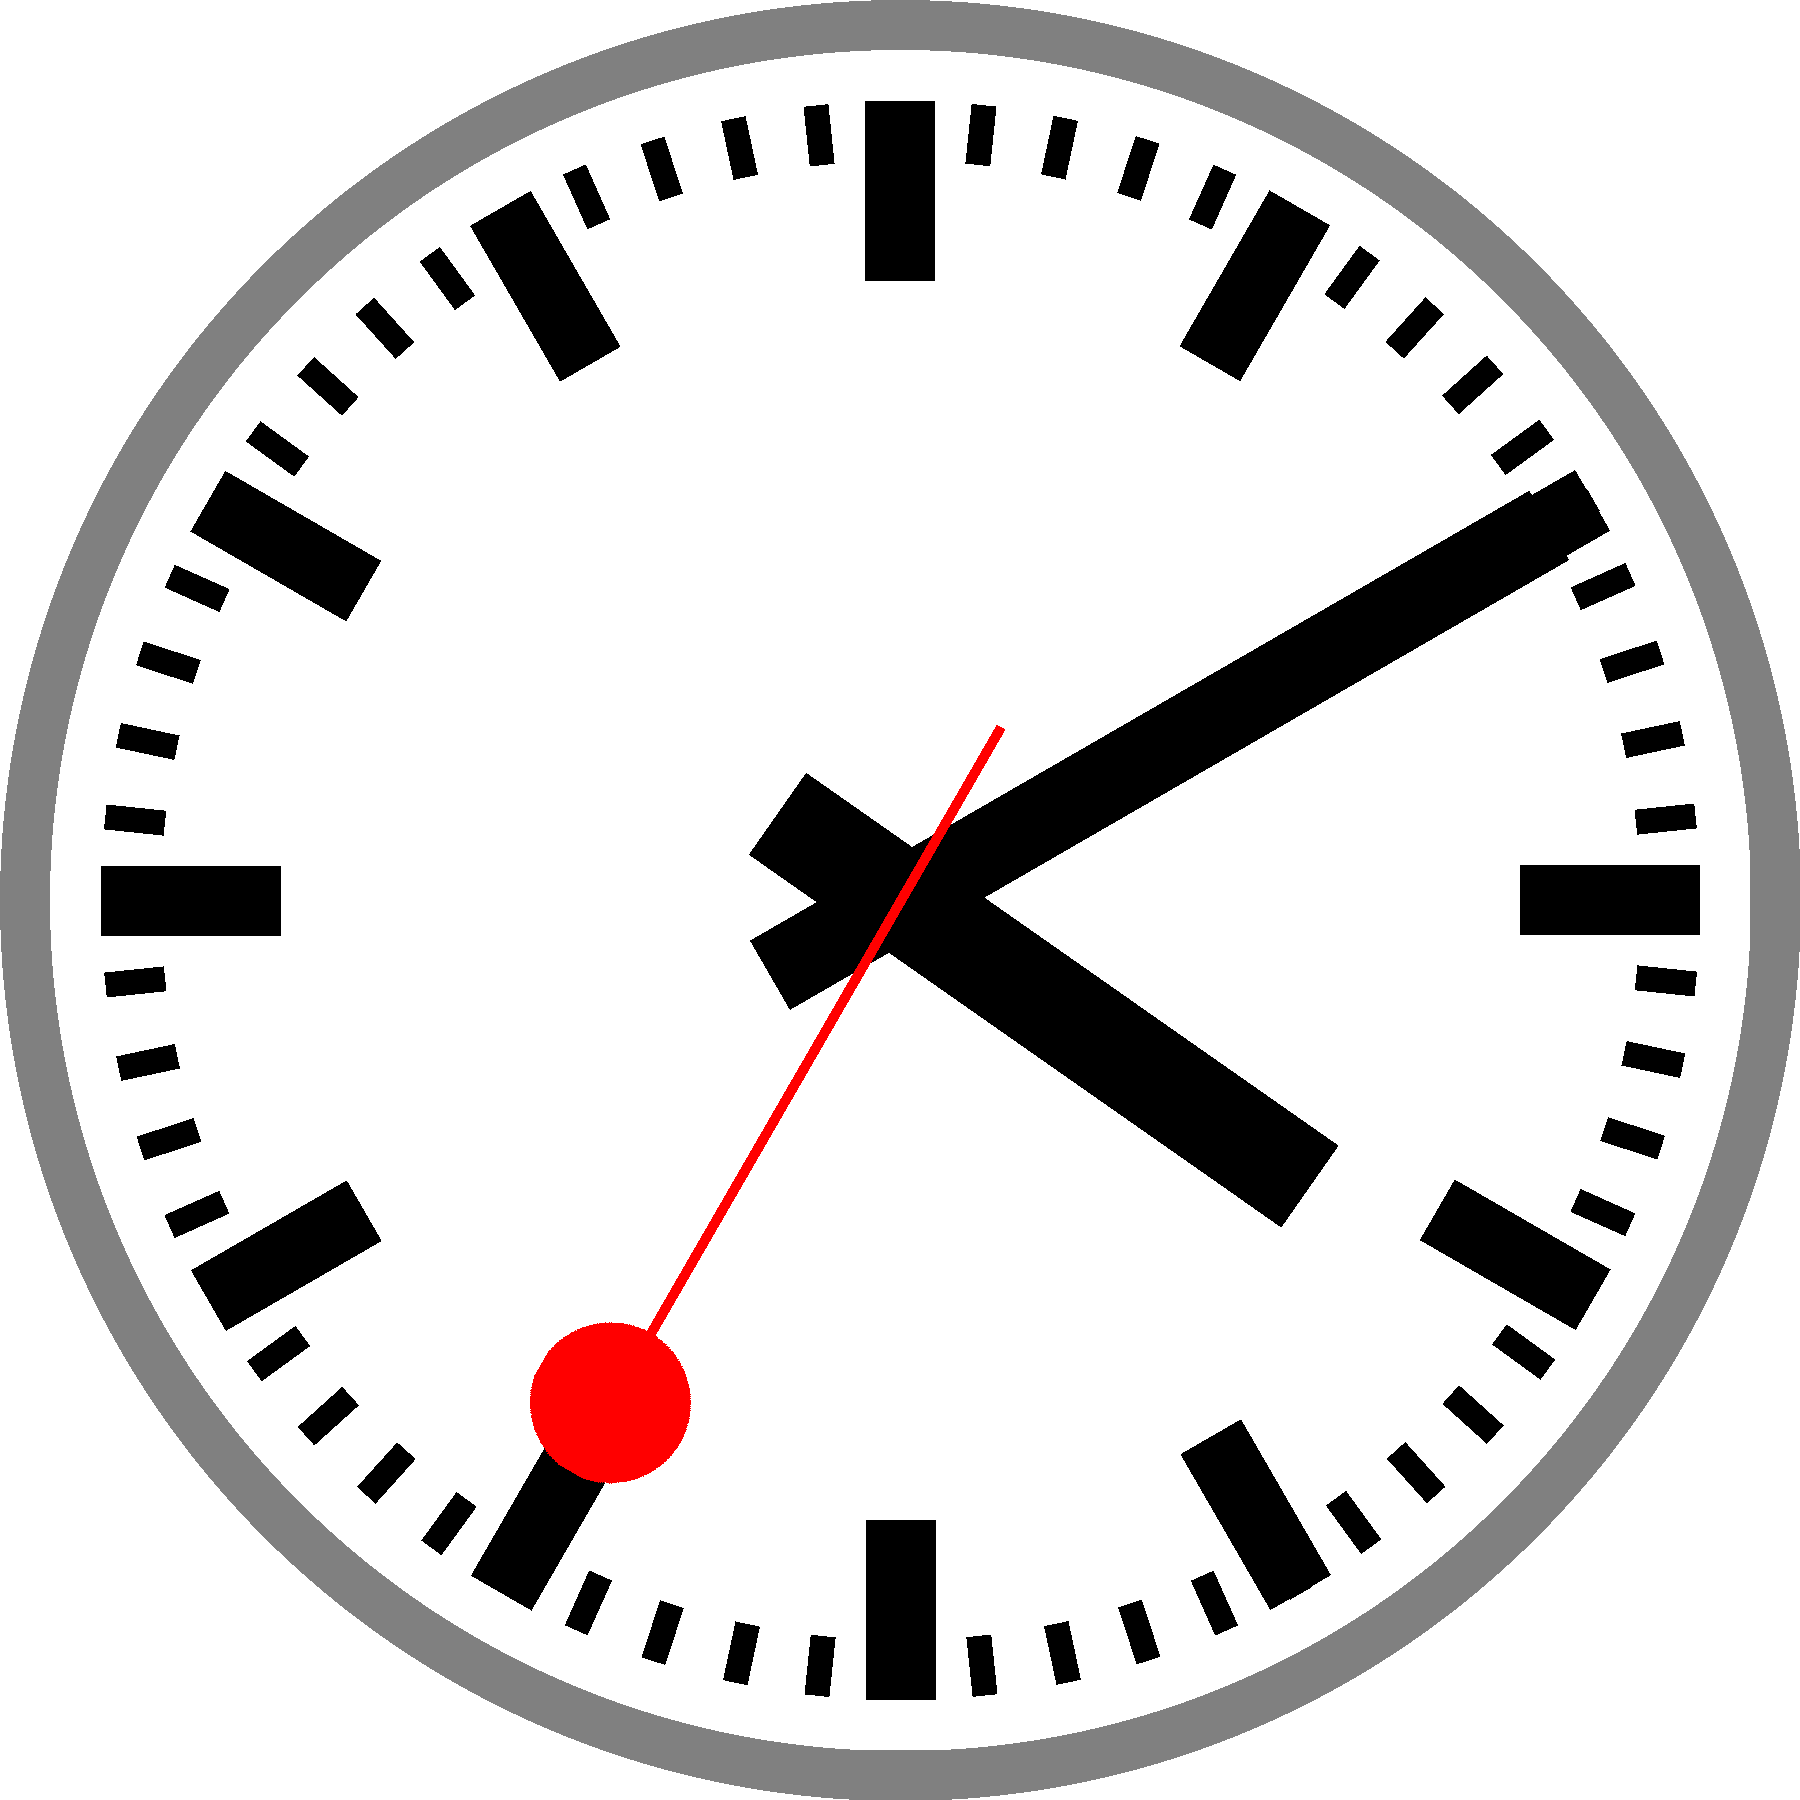

Die Uhr könnte zum Beispiel in die folgende Teilgrafiken zerlegt werden:

* Hintergrund
* Grössere Striche für Stunden
* Kleinere Striche für Minuten
* Stundenzeiger
* Minutenzeiger
* Sekundenzeiger

<img src="https://informa.inf.usi.ch/gridfs/courseFiles/md5/755a60cbd512a0c01de36133de02aa01" width="30%">
<img src="https://informa.inf.usi.ch/gridfs/courseFiles/md5/5cfd41a4e34ad4e9d93757c613c068d9" width="30%">
<img src="https://informa.inf.usi.ch/gridfs/courseFiles/md5/95d944d4f8e1dd64cb4babcdf376e97c" width="30%">


<img src="https://informa.inf.usi.ch/gridfs/courseFiles/md5/1cca46f6debfa84162e119be8902d928" width="20%">
<img src="https://informa.inf.usi.ch/gridfs/courseFiles/md5/d6f6a14b613b909936e42373ef41d4b0" width="20%">
<img src="https://informa.inf.usi.ch/gridfs/courseFiles/md5/29e25ec1818b3c6176d9465e80c2f164" width="20%">

Die obigen Bilder der einzelnen Teilgrafiken zeigen auch die Bounding Box (roter Rahmen) und die Fixierpositionen (oranges Kreuz) an. Die Bounding Box ist das kleinste horizontale Rechteck das alle Teile, auch möglicherweise transparente Teile, umschliesst. Die Fixierposition ist der Punkt, and dem zwei Grafiken beim Kombinieren ausgerichtet und überlagert werden. Er kann mit `fixiere` definiert werden, und wird von `kombiniere` verwendet.


Du könntest für das Erstellen der obigen Teilgrafiken zum Beispiel die folgenden Funktionen entwickeln:

```python
def hintergrund() -> Grafik:
  """Weisser Hintergrund und grauer Rand"""
```

```python
def stunden_zeiger(winkel: float) -> Grafik:
  """Nach oben zeigender Stundenzeiger"""
```

```python
def minuten_zeiger() -> Grafik:
  """Nach oben zeigender Minutenzeiger"""
```

```python
def sekunden_zeiger(winkel: float) -> Grafik:
  """Nach oben zeigender Sekundenzeiger"""
```

```python
def minuten_striche() -> Grafik:
  """Alle 60 Minuten-Striche"""
```

```python
def stunden_striche() -> Grafik:
  """Alle 12 Stunden-Striche"""
```

Du kannst somit jede Teilgrafik unabhängig entwickeln und anschauen.

### Hintergrund

In [ ]:
GRAU = rgb_farbe(128, 128, 128)

def hintergrund() -> Grafik:
    """Weisser Hintergrund und grauer Rand"""
    pass

### Erzeugen eines Zeigers

Was steht im Zentrum jeder Uhr? Eine Achse! Eine Achse um die sich die Zeiger drehen.

Wenn wir genau hinschauen sehen wir, dass wir viele der obigen Komponenten der Uhr zusammenbauen können, indem wir diese in ihrem Zentrum überlagern. Sowohl der Hintergrund als auch die Kreise mit den Minutenstrichen und den Stundenstrichen sind zentriert.

In einer echten Uhr hätten wir im Zentrum  eine Achse. In unserer PyTamaro Grafik ist dies ein guter Punkt für die Fixierpositionen der zu komponierenden Grafiken.

Wenn wir den Hintergrund und die zwei Strich-Kreise zusammenbauen wollen, so können wir dies mit `ueberlagere` tun. Dabei werden die Grafiken in ihren Zentren überlagert:

```python
ueberlagere(minutenstriche, stundenstriche)
```

Wir können aber auch die etwas generelleren Funktionen `fixiere` und `kombiniere` verwenden: zuerst verwenden wir `fixiere` um Grafiken mit Fixierungspunkten in ihrem Zentrum zu erhalten. Danach verwenden wir `kombiniere` um zwei solche Grafiken an ihren Fixierungspunkten übereinanderzulegen:

```python
kombiniere(
  fixiere("mitte", "mitte", minutenstriche),
  fixiere("mitte", "mitte", stundenstriche) 
)
```

Beide Ansätze führen zum selben Bild, aber der Ansatz mit `kombiniere` und `fixiere` bietet mehr Flexibilität: wir können die Fixierpositionen auf andere Orte als auf die Mitte der Grafik legen!

In einer echten Uhr sind auch die Zeiger an der Achse montiert. Die Achse geht an einem bestimmten Punkt durch den Zeiger durch. Wär's nicht schön, wenn wir dies auch hier so tun könnten? Vielleicht indem wir einen Zeiger mit einer entsprechenden Fixierposition bauen, bevor wir diesen auf die Achse (oder den Rest der Uhr) stecken?

Fixiertes langes Teil: <img src="https://informa.inf.usi.ch/gridfs/courseFiles/md5/49e85cbdf27bd7e01c471ba73e39656c">
<span style="padding-left: 1cm"></span> Fixiertes kurzes Teil: <img src="https://informa.inf.usi.ch/gridfs/courseFiles/md5/fc758dfb6d19089ab6b3da2877f67c6e"> <span style="padding-left: 1cm"></span> Zeiger: <img src="https://informa.inf.usi.ch/gridfs/courseFiles/md5/ee4d4edb0669dcaa3c1257b80ce35d73">

Und wir können! Wie? Wir können einen Zeiger als aus zwei Teilen gebaut anschauen, dem langen Teil auf der einen Seite der Achse, und dem kurzen Teil auf der anderen Seite der Achse.

Wenn wir den Zeiger aus diesen zwei Teilen zusammenbauen, indem wir `kombiniere` und `fixiere` verwenden, dann kriegen wir einen Zeiger mit der Fixierposition genau in der Mitte der Naht zwischen den zwei Teilen:

```python
kombiniere(
  fixiere("mitte", "unten", langes_teil),
  fixiere("mitte", "oben", kurzes_teil)
)
```

Die obige Abbildung zeigt die zwei fixierten Teile (mit den Fixierpositionen) und das Ergebnis des Kombinierens, den Zeiger (mit seiner Fixierposition). Nun können wir den Zeiger an dieser Fixierposition auf die Achse stecken. Oder ihn vorher noch um diese Fixierposition drehen...

In [ ]:
from pytamaro.de import (
    Grafik, 
    rechteck, 
    ueberlagere, kombiniere, fixiere, 
    oben_mitte, mitte, unten_mitte, 
    schwarz, weiss, rot,
    zeige_grafik
)

def stunden_zeiger(winkel: float) -> Grafik:
    """Nach oben zeigender Stundenzeiger"""
    pass

def minuten_zeiger() -> Grafik:
    """Nach oben zeigender Minutenzeiger"""
    pass

def sekunden_zeiger(winkel: float) -> Grafik:
    """Nach oben zeigender Sekundenzeiger"""
    pass

# Rufe die Funktion zeige_grafik(...) auf um die verschiedenen Zeiger anzuzeigen

# TODO

### Drehen eines Zeigers

Wenn Du gemäss der obigen Anleitung einen Zeiger baust, zeigt dieser gerade nach oben.

Wie können wir den Zeiger drehen so dass er die gewünschte Zeit anzeigt?

Die Funktion `drehe` dreht eine Grafik um deren Fixierposition. Sie tut das im Gegenuhrzeigersinn. Wir möchten den Zeiger aber im Uhrzeigersinn drehen. Dazu können wir der Funktion `drehe` einen _negativen_ Winkel übergeben. Zum Beispiel `drehe(-30, g)` dreht die Grafik g um 30 Grad im Uhrzeigersinn.

Wenn Du also zum Beispiel einen Minutenzeiger auf "5 Minuten" stellen willst, musst Du ihn um 5 Minuten * 6 Grad/Minute = 30 Grad im Uhrzeigersinn drehen (bei 360 Grad für eine volle Drehung braucht es für jede der 60 Minuten 6 Grad).


### Erzeugen eines Minuten-Strichs

Wie können wir einen Minuten-Strich an der richtigen Position an der Uhr anbringen?

Wir könnten einen Strich als eine Art Zeiger ansehen, nur dass der Strich nicht bis ins Zentrum der Uhr geht (die Achse geht nicht durch den Strich).

Wir können allerdings einen Strich (ähnlich wie einen Zeiger) auch als Komposition von zwei Teilen anschauen. Nur ist eines der zwei Teile durchsichtig! Wir haben also ein durchsichtiges Teil vom Zentrum der Uhr bis zum inneren Radius des Strichs, und dann ein schwarzes Teil von dort bis zum äusseren Radius des Strichs.

Fixierter Strich: <img src="https://informa.inf.usi.ch/gridfs/courseFiles/md5/5155249cc114456188bf5926637e9198">
Fixierter Abstand: <img src="https://informa.inf.usi.ch/gridfs/courseFiles/md5/d11230bbc6694765dcc13d3e1fab824b">
Strich mit Abstand: <img src="https://informa.inf.usi.ch/gridfs/courseFiles/md5/aedf9b54413c4bcde1dafec1436df6fd">
Unten fixiert: <img src="https://informa.inf.usi.ch/gridfs/courseFiles/md5/27d472a6fb5c7e2076efa09b4664276d">

Wir können die zwei Teile (den schwarzen Strich und den transparenten Abstand) auf die gleiche Weise fixieren und zusammenbauen wie die Teile eines Zeigers:

```python
strich_mit_abstand = kombiniere(
  fixiere("mitte", "unten", strich),
  fixiere("mitte", "oben", abstand)
)
```

Nun müssen wir nur noch den Fixierpunkt auf das untere Ende legen, und dann sind wir bereit, den Strich um einen beliebigen Winkel zu drehen und auf die Achse zu stecken.

```python
fixiere("mitte", "unten", strich_mit_abstand)
```

Nun brauchen wir nur noch eine genügende Anzahl Striche, jeder mit einem anderen Drehwinkel. Die Stunden-Striche bauen wir auf die gleiche Weise.

### Komposition der Einzelteile in eine Uhr

Sobald Du die sechs obigen Funktionen (unabhänging voneinander) implementiert und getestet hast, kannst Du die von ihnen erzeugten Teilgrafiken zusammenbauen. Dazu könntest Du zum Beispiel die folgende Funktion entwickeln:

```python
def uhr(stunden: int, minuten: int, sekunden: int) -> Grafik:
  pass
```

Diese könnte dann zum Beispiel mit `zeige_grafik(uhr(5, 10, 14))` aufgerufen werden, um die Zeit 5:10:14 anzuzeigen.

In [ ]:
def uhr(stunden: int, minuten: int, sekunden: int) -> Grafik:
    """Uhr, welche die angegebene Zeit anzeigt"""
    pass